# 03 - M1 (CNN do zero): E2 e E3

Parte 1 do projeto. Treina o M1 e roda os experimentos da Parte 1:

- **E2 (aumento de dados):** sem aumento, SpecAugment, mixup, ruído e todas juntas; 3 sementes; fold 0 de validação; avaliação no teste limpo.
- **E3 (robustez a ruído):** os modelos "sem" e "todas" no teste com ruído da ESC-50 (fold 5, nunca visto no treino) a 20, 10, 5 e 0 dB.

O código está em `src/birdclef/` (`treino.py`, `experimentos.py`, `graficos.py`); execuções já salvas em `checkpoints/` são puladas.
No Colab use GPU (Ambiente de execução → Alterar o tipo → T4).

In [1]:
# Preparação no Colab (no computador local, rode a partir da raiz do repositório)
import sys, os
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/birdclef-dl"):
        !git clone -q https://github.com/arbcaio/birdclef-dl.git /content/birdclef-dl
    %cd /content/birdclef-dl
    !pip install -q -e .
    DRIVE = "/content/drive/MyDrive/birdclef-dl/dados"
    for sub in ["bruto", "ruido", "subconjunto", "espectrogramas"]:
        if not os.path.exists(f"dados/{sub}") and os.path.exists(f"{DRIVE}/{sub}"):
            !ln -s {DRIVE}/{sub} dados/{sub}
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

In [2]:
import pandas as pd
from IPython.display import Image, display
from birdclef import experimentos, graficos, modelos

X, janelas, R = experimentos.carregar_dados()
m1 = modelos.criar("M1", janelas.primary_label.nunique())
print(m1); print(f"{modelos.n_parametros(m1):,} parâmetros")

CNN(
  (extrator): Sequential(
    (0): BlocoConv(
      (camadas): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): BlocoConv(
      (camadas): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): BlocoConv(
      (camadas): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
 

## E2: aumento de dados

In [3]:
e2 = experimentos.e2(X, janelas, R)
pd.read_csv("resultados/e2/e2_resumo.csv", header=[0, 1], index_col=0).round(3)

{'aumento': 'sem', 'semente': 42, 'epocas': 30, 'melhor_epoca': 28, 'minutos': 10.618889649709066, 'val_f1_macro': 0.825778499200361, 'val_acc_top1': 0.8270833333333333, 'val_acc_top3': 0.9416666666666667, 'val_map': 0.870774402182872, 'teste_f1_macro': 0.8528210026522061, 'teste_acc_top1': 0.8533333333333334, 'teste_acc_top3': 0.9433333333333334, 'teste_map': 0.8995263957358313}


{'aumento': 'sem', 'semente': 43, 'epocas': 18, 'melhor_epoca': 12, 'minutos': 6.180774482091268, 'val_f1_macro': 0.8129373208308163, 'val_acc_top1': 0.8083333333333333, 'val_acc_top3': 0.9229166666666667, 'val_map': 0.8673341410567049, 'teste_f1_macro': 0.8381099651090373, 'teste_acc_top1': 0.8366666666666667, 'teste_acc_top3': 0.9333333333333333, 'teste_map': 0.905283807623087}


{'aumento': 'sem', 'semente': 44, 'epocas': 28, 'melhor_epoca': 22, 'minutos': 9.638225666681926, 'val_f1_macro': 0.8348005990717391, 'val_acc_top1': 0.8333333333333334, 'val_acc_top3': 0.925, 'val_map': 0.8575728352797416, 'teste_f1_macro': 0.8421388001597311, 'teste_acc_top1': 0.84, 'teste_acc_top3': 0.955, 'teste_map': 0.9043501135534717}


{'aumento': 'specaug', 'semente': 42, 'epocas': 25, 'melhor_epoca': 19, 'minutos': 8.651553932825724, 'val_f1_macro': 0.8356834423557729, 'val_acc_top1': 0.8375, 'val_acc_top3': 0.9375, 'val_map': 0.8842727172211353, 'teste_f1_macro': 0.8611857298904898, 'teste_acc_top1': 0.8616666666666667, 'teste_acc_top3': 0.95, 'teste_map': 0.9167956871114462}


{'aumento': 'specaug', 'semente': 43, 'epocas': 30, 'melhor_epoca': 30, 'minutos': 10.40230932633082, 'val_f1_macro': 0.8591210748489724, 'val_acc_top1': 0.8583333333333333, 'val_acc_top3': 0.95, 'val_map': 0.8966158980429993, 'teste_f1_macro': 0.8788884029766606, 'teste_acc_top1': 0.8783333333333333, 'teste_acc_top3': 0.9566666666666667, 'teste_map': 0.9208884130431771}


...

{'aumento': 'ruido', 'semente': 44, 'epocas': 30, 'melhor_epoca': 25, 'minutos': 10.377506991227468, 'val_f1_macro': 0.8627962147007121, 'val_acc_top1': 0.8625, 'val_acc_top3': 0.9458333333333333, 'val_map': 0.8968471183597861, 'teste_f1_macro': 0.8772774096505132, 'teste_acc_top1': 0.8766666666666667, 'teste_acc_top3': 0.9633333333333334, 'teste_map': 0.9223945607919519}


{'aumento': 'todas', 'semente': 42, 'epocas': 28, 'melhor_epoca': 22, 'minutos': 9.977704660097759, 'val_f1_macro': 0.8577508115418219, 'val_acc_top1': 0.8583333333333333, 'val_acc_top3': 0.95, 'val_map': 0.903006806880984, 'teste_f1_macro': 0.8791082517466464, 'teste_acc_top1': 0.8766666666666667, 'teste_acc_top3': 0.9616666666666667, 'teste_map': 0.9265350930585216}


{'aumento': 'todas', 'semente': 43, 'epocas': 30, 'melhor_epoca': 26, 'minutos': 10.61054915189743, 'val_f1_macro': 0.8560134217102826, 'val_acc_top1': 0.85625, 'val_acc_top3': 0.9395833333333333, 'val_map': 0.8992115182551362, 'teste_f1_macro': 0.870383236626744, 'teste_acc_top1': 0.87, 'teste_acc_top3': 0.9533333333333334, 'teste_map': 0.9297900081947672}


{'aumento': 'todas', 'semente': 44, 'epocas': 30, 'melhor_epoca': 30, 'minutos': 10.54533565044403, 'val_f1_macro': 0.8586726975631562, 'val_acc_top1': 0.8583333333333333, 'val_acc_top3': 0.9541666666666667, 'val_map': 0.8974934723688763, 'teste_f1_macro': 0.8774143394940825, 'teste_acc_top1': 0.8766666666666667, 'teste_acc_top3': 0.9616666666666667, 'teste_map': 0.9399095560305243}


epocas        melhor_epoca        minutos        val_f1_macro         \
           mean    std         mean    std    mean    std         mean    std   
aumento                                                                         
sem      25.333  6.429       20.667  8.083   8.813  2.331        0.825  0.011   
specaug  28.333  2.887       25.667  5.859   9.865  1.053        0.846  0.012   
mixup    28.667  2.309       25.333  4.619  10.097  0.704        0.836  0.005   
ruido    30.000  0.000       26.000  1.000  10.397  0.019        0.858  0.004   
todas    29.333  1.155       26.000  4.000  10.378  0.348        0.857  0.001   

        val_acc_top1         ... val_map        teste_f1_macro         \
                mean    std  ...    mean    std           mean    std   
aumento                      ...                                        
sem            0.823  0.013  ...   0.865  0.007          0.844  0.008   
specaug        0.847  0.011  ...   0.890  0.006          0.870  0.009   
mixup          0.836  0.005  ...   0.878  0.005          0.872  0.002   
ruido          0.858  0.004  ...   0.894  0.006          0.882  0.006   
todas          0.858  0.001  ...   0.900  0.003          0.876  0.005   

        teste_acc_top1        teste_acc_top3        teste_map         
                  mean    std           mean    std      mean    std  
aumento                                                               
sem              0.843  0.009          0.944  0.011     0.903  0.003  
specaug          0.870  0.008          0.953  0.003     0.921  0.004  
mixup            0.872  0.001          0.951  0.005     0.923  0.003  
ruido            0.881  0.005          0.963  0.003     0.928  0.005  
todas            0.874  0.004          0.959  0.005     0.932  0.007  

[5 rows x 22 columns]

## E3: robustez a ruído

In [4]:
e3 = experimentos.e3(janelas)
pd.read_csv("resultados/e3/e3_resumo.csv", header=[0, 1], index_col=[0, 1]).round(3)

f1_macro        acc_top1        acc_top3           map       
                  mean    std     mean    std     mean    std   mean    std
aumento teste                                                              
sem     limpo    0.844  0.008    0.843  0.009    0.944  0.011  0.903  0.003
        20 dB    0.847  0.012    0.846  0.013    0.944  0.006  0.908  0.006
        10 dB    0.837  0.012    0.836  0.015    0.937  0.004  0.896  0.003
        5 dB     0.818  0.013    0.817  0.016    0.922  0.006  0.876  0.007
        0 dB     0.786  0.023    0.784  0.026    0.901  0.008  0.843  0.008
todas   limpo    0.876  0.005    0.874  0.004    0.959  0.005  0.932  0.007
        20 dB    0.881  0.010    0.881  0.010    0.959  0.007  0.934  0.006
        10 dB    0.871  0.011    0.870  0.012    0.952  0.009  0.923  0.005
        5 dB     0.867  0.007    0.866  0.008    0.947  0.011  0.911  0.006
        0 dB     0.839  0.011    0.835  0.015    0.934  0.006  0.896  0.008

## Figuras

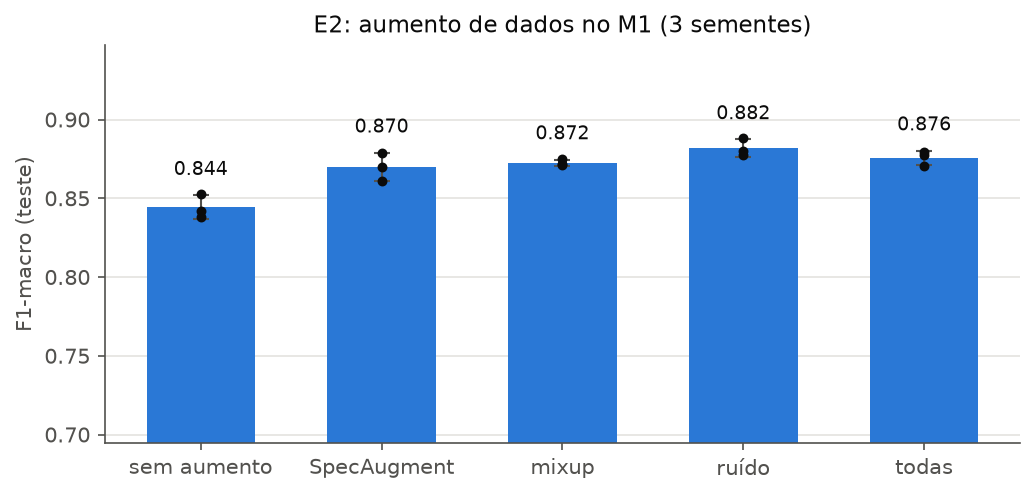

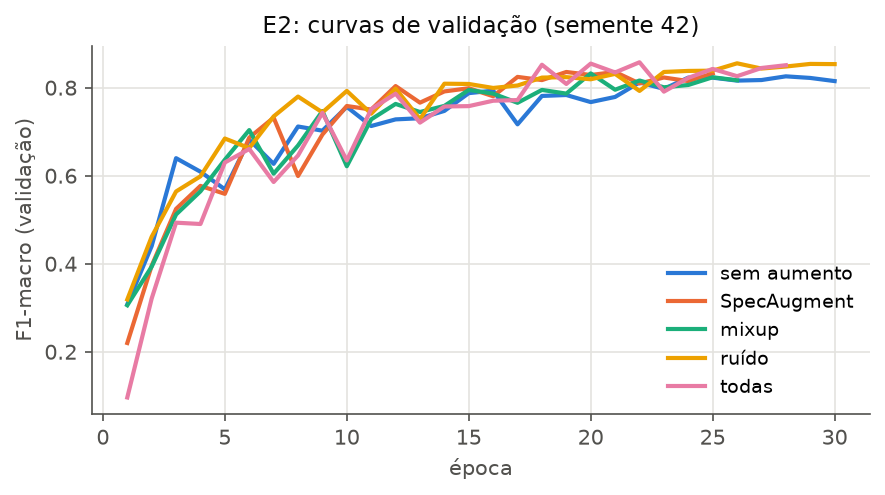

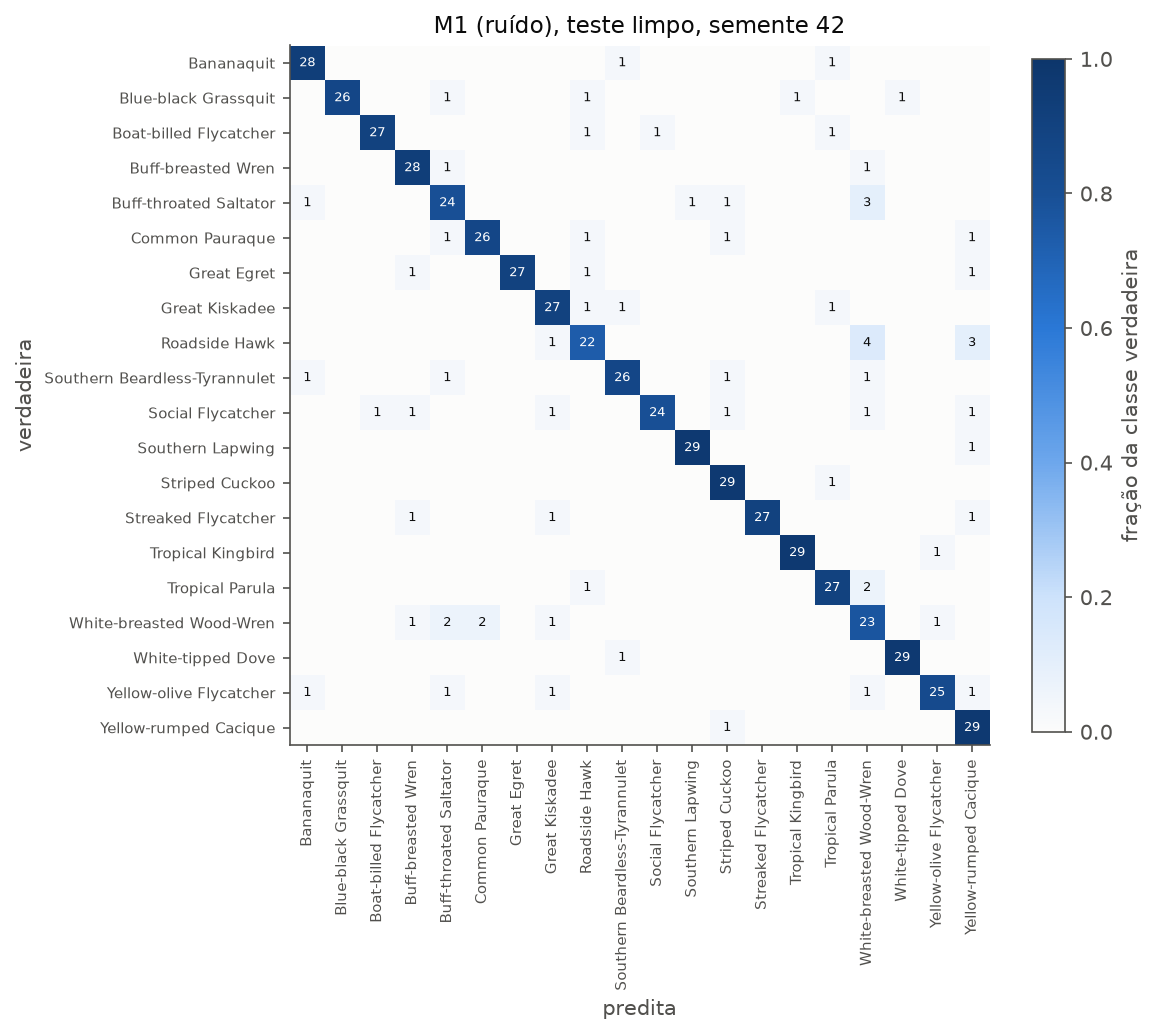

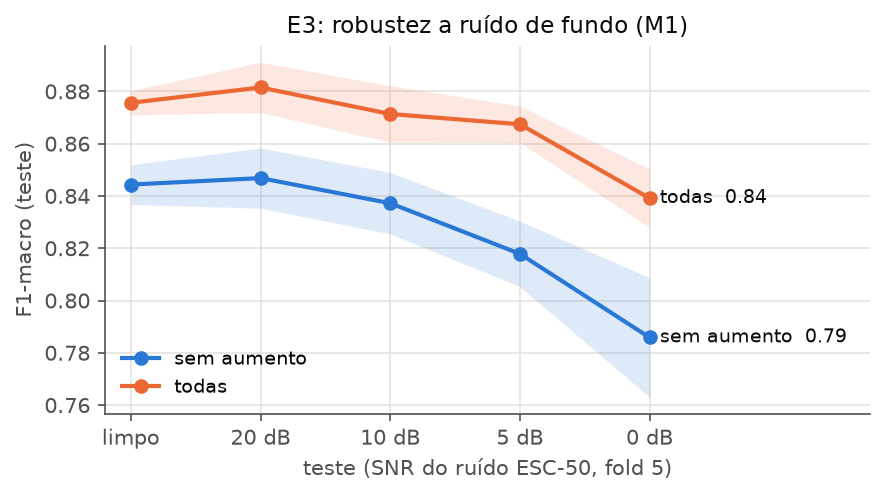

In [5]:
graficos.todas()
for f in ["e2/e2_f1_teste.png", "e2/e2_curvas.png", "e2/matriz_confusao.png", "e3/e3_snr.png"]:
    display(Image(f"resultados/{f}"))